# Who Survived the Titanic?

The question: given what was written on a passenger's ticket and manifest entry, can we predict whether they survived?

Approach in short:
1. Look at the raw passenger list and where it has gaps.
2. Turn names, tickets and cabins into features that carry real signal (title, deck, fare per person, family size).
3. Compare three model families with stratified cross-validation, tune the strongest, and check it on a held-out test set.
4. Explain what the final model relies on.

In [1]:
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sys.path.append("../src")
from features import CATEGORICAL, NUMERIC, TitleAgeImputer, build_features

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 7

## 1. The raw passenger list

In [2]:
raw = pd.read_csv("../data/titanic.csv")
print(raw.shape)
raw.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
gaps = (raw.isna().mean() * 100).round(1).sort_values(ascending=False)
gaps[gaps > 0].to_frame("% missing")

,% missing
Cabin,77.1
Age,19.9
Embarked,0.2


Cabin is mostly empty (77%), Age is missing for about a fifth of passengers, and Embarked for two. Rather than dropping Cabin, I keep only its first letter (the deck), with `U` for unknown, because "no cabin recorded" is itself informative: it was far more common in third class.

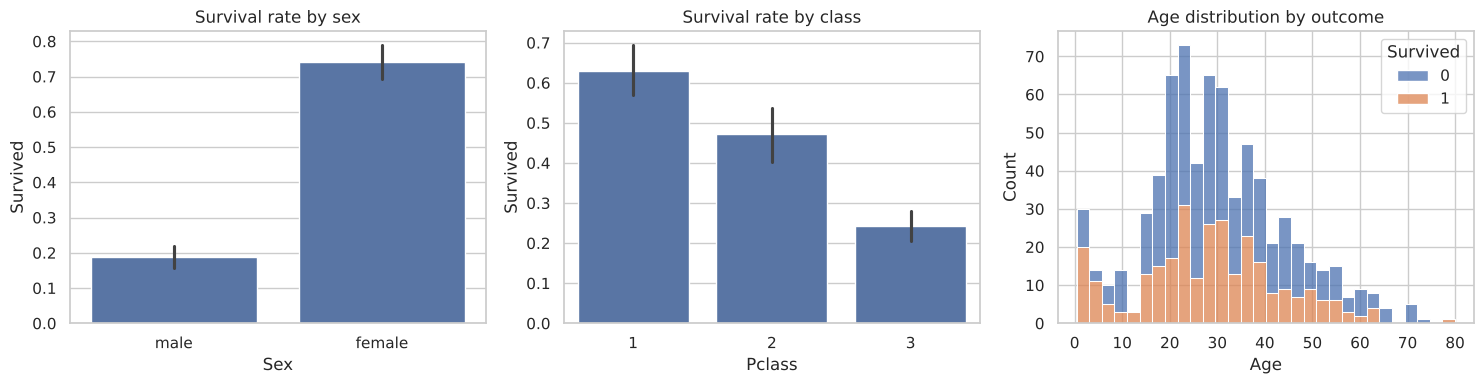

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=raw, x="Sex", y="Survived", ax=axes[0])
sns.barplot(data=raw, x="Pclass", y="Survived", ax=axes[1])
sns.histplot(data=raw, x="Age", hue="Survived", bins=30, multiple="stack", ax=axes[2])
axes[0].set_title("Survival rate by sex")
axes[1].set_title("Survival rate by class")
axes[2].set_title("Age distribution by outcome")
plt.tight_layout()
plt.show()

Sex and class dominate: about 74% of women survived against 19% of men, and first class survived at roughly 2.5x the rate of third. Young children also stand out on the left of the age chart.

## 2. Feature engineering

All transforms live in `src/features.py` so training and prediction use identical logic:

| Feature | Built from | Why |
|---|---|---|
| `Title` | Name | Captures sex, age group and status in one field ("Master" = boy) |
| `Deck` | Cabin | Proxy for location on the ship; `U` = no cabin recorded |
| `FamilySize`, `TravelGroup` | SibSp + Parch | Very small and very large groups fared differently |
| `FarePerPerson` | Fare / passengers on the same ticket, log-scaled | Raw fare double-counts shared tickets |
| `Age` | Age, gaps filled with the median for the passenger's title | Inside the pipeline, to avoid leakage |

In [5]:
X = build_features(raw)
y = raw["Survived"]
X.head()

,Age,FarePerPerson,FamilySize,Pclass,Sex,Embarked,Title,Deck,TravelGroup
0,22.0,2.110213,2,3,male,S,Mr,U,small
1,38.0,4.280593,2,1,female,C,Mrs,C,small
2,26.0,2.188856,1,3,female,S,Miss,U,alone
3,35.0,3.316003,2,1,female,S,Mrs,C,small
4,35.0,2.202765,1,3,male,S,Mr,U,alone


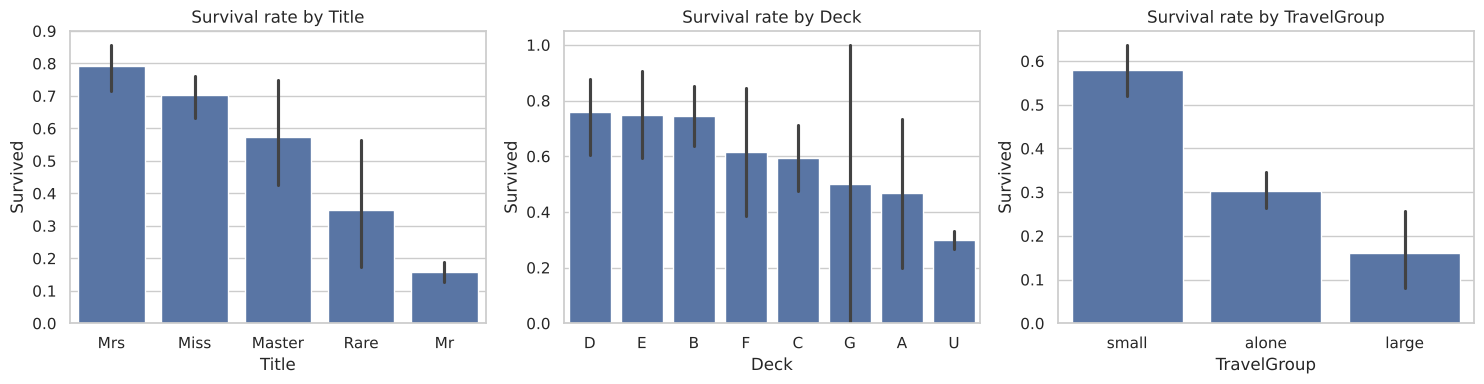

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Title", "Deck", "TravelGroup"]):
    order = X.join(y).groupby(col)["Survived"].mean().sort_values(ascending=False).index
    sns.barplot(x=X[col], y=y, order=order, ax=ax)
    ax.set_title(f"Survival rate by {col}")
plt.tight_layout()
plt.show()

The engineered features separate outcomes well: "Master" (boys) survived far more often than "Mr", passengers travelling alone or in large groups did worse than small families, and decks B, D and E outperformed unknown cabins.

## 3. Train / test split and model comparison

I hold out 20% of passengers as a final test set and never touch it until the end. Model selection uses 5-fold stratified cross-validation on the remaining 80%.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

encode = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])

def make_model(estimator):
    return Pipeline([("age", TitleAgeImputer()), ("encode", encode), ("model", estimator)])

candidates = {
    "Logistic regression": LogisticRegression(max_iter=2000, C=0.5),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, random_state=RANDOM_STATE),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for label, est in candidates.items():
    scores = cross_validate(make_model(est), X_train, y_train, cv=cv, scoring=["accuracy", "roc_auc", "f1"])
    rows.append({
        "model": label,
        "accuracy": scores["test_accuracy"].mean(),
        "roc_auc": scores["test_roc_auc"].mean(),
        "f1": scores["test_f1"].mean(),
        "acc_std": scores["test_accuracy"].std(),
    })
comparison = pd.DataFrame(rows).set_index("model").round(3).sort_values("roc_auc", ascending=False)
comparison

,accuracy,roc_auc,f1,acc_std
model,,,,
Random forest,0.829,0.892,0.760,0.018
Gradient boosting,0.824,0.890,0.762,0.016
Logistic regression,0.823,0.867,0.762,0.010


All three land close together, which says the features are doing most of the work. I tune the two tree models, since they have the most room to improve with settings.

## 4. Tuning

In [8]:
search_spaces = {
    "Random forest": (RandomForestClassifier(random_state=RANDOM_STATE), {
        "model__n_estimators": [300, 600],
        "model__max_depth": [5, 8, None],
        "model__min_samples_leaf": [1, 3, 5],
        "model__max_features": ["sqrt", 0.5],
    }),
    "Gradient boosting": (HistGradientBoostingClassifier(random_state=RANDOM_STATE), {
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [3, 5, None],
        "model__max_leaf_nodes": [15, 31],
        "model__l2_regularization": [0.0, 1.0],
    }),
}

tuned = {}
for label, (est, grid) in search_spaces.items():
    search = GridSearchCV(make_model(est), grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[label] = search
    print(f"{label}: CV ROC-AUC {search.best_score_:.3f}")
    print("   ", {k.replace("model__", ""): v for k, v in search.best_params_.items()})

best_label = max(tuned, key=lambda k: tuned[k].best_score_)
final_model = tuned[best_label].best_estimator_
print("\nSelected:", best_label)

Random forest: CV ROC-AUC 0.897
    {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 300}


Gradient boosting: CV ROC-AUC 0.893
    {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_depth': None, 'max_leaf_nodes': 15}

Selected: Random forest


## 5. Final check on the held-out test set

Test ROC-AUC: 0.841

              precision    recall  f1-score   support

        Died       0.83      0.92      0.87       110
    Survived       0.84      0.71      0.77        69

    accuracy                           0.84       179
   macro avg       0.84      0.81      0.82       179
weighted avg       0.84      0.84      0.83       179



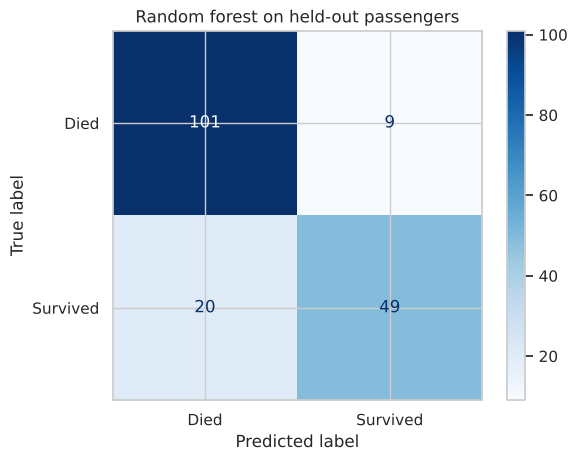

In [9]:
pred = final_model.predict(X_test)
prob = final_model.predict_proba(X_test)[:, 1]
print(f"Test ROC-AUC: {roc_auc_score(y_test, prob):.3f}\n")
print(classification_report(y_test, pred, target_names=["Died", "Survived"]))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Died", "Survived"], cmap="Blues")
plt.title(f"{best_label} on held-out passengers")
plt.show()

## 6. What the model relies on

Permutation importance shuffles one feature at a time on the test set and measures how much ROC-AUC drops. It works on the original columns, so it's easier to read than one-hot coefficients.

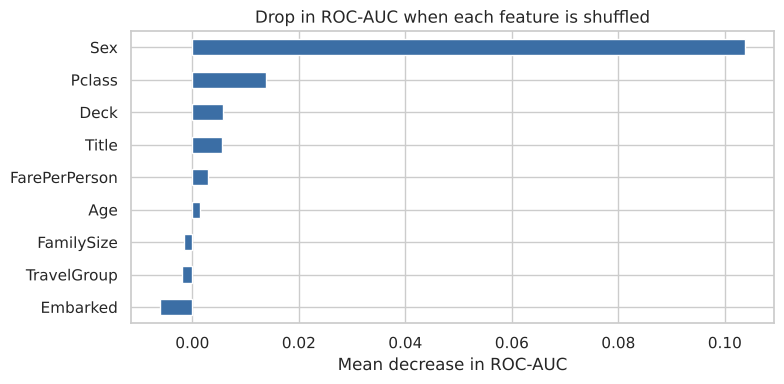

In [10]:
imp = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE)
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
importance.plot.barh(figsize=(8, 4), color="#3b6ea5")
plt.title("Drop in ROC-AUC when each feature is shuffled")
plt.xlabel("Mean decrease in ROC-AUC")
plt.tight_layout()
plt.show()

## 7. Save the model and try it

In [11]:
final_model.fit(X, y)  # refit on every labelled passenger before saving
joblib.dump(final_model, "../models/survival_model.joblib")

examples = pd.DataFrame([
    {"Name": "Doe, Mrs. Jane", "Sex": "female", "Pclass": 1, "Age": 38, "SibSp": 1, "Parch": 0,
     "Fare": 80.0, "Ticket": "X1", "Cabin": "C85", "Embarked": "C"},
    {"Name": "Roe, Mr. John", "Sex": "male", "Pclass": 3, "Age": 24, "SibSp": 0, "Parch": 0,
     "Fare": 7.9, "Ticket": "X2", "Cabin": np.nan, "Embarked": "S"},
    {"Name": "Poe, Master. Sam", "Sex": "male", "Pclass": 2, "Age": 5, "SibSp": 1, "Parch": 2,
     "Fare": 30.0, "Ticket": "X3", "Cabin": np.nan, "Embarked": "S"},
])
examples["P(survive)"] = final_model.predict_proba(build_features(examples))[:, 1].round(2)
examples[["Name", "Sex", "Pclass", "Age", "P(survive)"]]

,Name,Sex,Pclass,Age,P(survive)
0,"Doe, Mrs. Jane",female,1,38,0.99
1,"Roe, Mr. John",male,3,24,0.03
2,"Poe, Master. Sam",male,2,5,0.90


## Takeaways

- **Sex and title carry most of the signal**, consistent with "women and children first".
- **Class and fare per person** add a clear second layer: wealth bought proximity to the lifeboats.
- **Feature engineering mattered more than model choice.** Three very different models scored within a few points of each other once title, deck and fare per person were in place.
- Limitation: 891 passengers is a small sample, so the scores move a few points between random splits.